# Pre-processing

In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [2]:
!ls {path}

auto_test  test  train	val


In [3]:
from torchvision import transforms, datasets

base = path

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [4]:
# only testing
img, label = train[0]
img, label

(tensor([[[-0.5938, -0.5596, -0.5253,  ..., -0.6623, -0.7308, -0.8164],
          [-0.5938, -0.5596, -0.5596,  ..., -0.6794, -0.7650, -0.8507],
          [-0.5767, -0.5767, -0.5424,  ..., -0.6965, -0.7650, -0.8164],
          ...,
          [-1.5014, -1.5014, -1.4672,  ..., -0.7822, -0.7650, -0.7650],
          [-1.5014, -1.5185, -1.4672,  ..., -0.7308, -0.7479, -0.7479],
          [-1.5014, -1.5014, -1.4843,  ..., -0.7137, -0.7137, -0.7479]],
 
         [[-0.4776, -0.4426, -0.4076,  ..., -0.5476, -0.6176, -0.7052],
          [-0.4776, -0.4426, -0.4426,  ..., -0.5651, -0.6527, -0.7402],
          [-0.4601, -0.4601, -0.4251,  ..., -0.5826, -0.6527, -0.7052],
          ...,
          [-1.4055, -1.4055, -1.3704,  ..., -0.6702, -0.6527, -0.6527],
          [-1.4055, -1.4230, -1.3704,  ..., -0.6176, -0.6352, -0.6352],
          [-1.4055, -1.4055, -1.3880,  ..., -0.6001, -0.6001, -0.6352]],
 
         [[-0.2532, -0.2184, -0.1835,  ..., -0.3230, -0.3927, -0.4798],
          [-0.2532, -0.2184,

In [5]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

In [6]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'0': 2286, '1': 1046, '2': 1516, '3': 757, '4': 173}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [7]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 5778 (69.95%) | Classes: {'0': '2286 (39.6%)', '1': '1046 (18.1%)', '2': '1516 (26.2%)', '3': '757 (13.1%)', '4': '173 (3.0%)'}
val   | Total:  826 (10.00%) | Classes: {'0': '328 (39.7%)', '1': '153 (18.5%)', '2': '212 (25.7%)', '3': '106 (12.8%)', '4': '27 (3.3%)'}
test  | Total: 1656 (20.05%) | Classes: {'0': '639 (38.6%)', '1': '296 (17.9%)', '2': '447 (27.0%)', '3': '223 (13.5%)', '4': '51 (3.1%)'}


In [8]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [9]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 5778


In [10]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader = DataLoader(val, batch_size=32, shuffle=False)
test_loader = DataLoader(test, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([1, 0, 3, 1, 2, 1, 0, 0, 2, 3])


In [11]:

# Brightness/contrast standardization + joint-centered crop -> every image becomes 224 x 104 grayscale.
# The functions below are copied from Sara's notebook (mufsal_pre2) without any change.

import cv2, numpy as np
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# ---------- Settings ----------
SIZE_STD = 224
WINDOW_H_STD = 104         # output = 224 x 104
TARGET_MEAN = 110.0        # every image gets this mean brightness (via a gamma curve, no clipping)

MIN_CONTRAST = 4                        # weak valley = joint not clear (usual band)
WIDE_PROM = 10                          # stricter depth needed when the joint is far from its usual place


def joint_row_std(gray, lo=0.40, hi=0.70, min_prom=MIN_CONTRAST):
    """Row of the joint gap (darkest valley in the central columns) or None."""
    H, W = gray.shape
    cols = gray[:, int(W * .25):int(W * .75)].astype(np.float32)
    cols = np.minimum(cols, np.percentile(cols, 95))        # metal implants / very bright parts must not decide
    prof = gaussian_filter1d(np.median(cols, axis=1), sigma=H * 0.02)   # median = robust to a plate on one side
    a, b = int(H * lo), int(H * hi)
    pk, pr = find_peaks(-prof[a:b], prominence=min_prom)
    return None if len(pk) == 0 else a + int(pk[np.argmax(pr["prominences"])])


def normalize_std(g):
    """Uniform brightness / contrast WITHOUT cutting off pixels.
    1) stretch the 0.5-99.5 percentile range to 5-250 (only ~1% of the pixels are touched)
    2) CLAHE (local contrast, same settings as the original pipeline)
    3) gamma curve chosen per image so the mean brightness = TARGET_MEAN
       (a gamma curve moves the mid-tones only: black stays black, white stays white, nothing is clipped)."""
    lo, hi = np.percentile(g, (0.5, 99.5))
    f = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
    g = (5 + f * 245).astype(np.uint8)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    return match_mean_std(g)


def match_mean_std(g):
    """Gamma curve so that the mean brightness = TARGET_MEAN (black stays black, white stays white)."""
    x = g.astype(np.float32) / 255
    a, b = np.log(0.2), np.log(5.0)                         # search the gamma in log-space (bisection)
    for _ in range(25):
        m = (a + b) / 2
        if (x ** np.exp(m)).mean() * 255 > TARGET_MEAN:     # still too bright -> larger gamma (darker)
            a = m
        else:
            b = m
    return np.round(x ** np.exp((a + b) / 2) * 255).astype(np.uint8)


def standardize_std(img):
    """PIL image -> (standardized PIL image 224x104, status).
    status: ok         joint found in its usual place (shift limited to +/-16 px)
            off_center a valley far from the usual place -> NOT trusted: crop stays at the usual position (flagged for review)
            edge       a clear valley only very near the top/bottom border -> joint probably cut in the original
            fallback   no joint found -> crop around the most likely position"""
    g = np.array(img.convert("L").resize((SIZE_STD, SIZE_STD)))

    g = normalize_std(g)

    # 2) joint-centered crop (detect on the standardized image)
    status = "ok"
    row = joint_row_std(g)                                          # tier 1: usual band (40-70% of the height)
    if row is not None:
        row = int(np.clip(row, 124 - 16, 124 + 16))                 # small shift only: protects against wrong detections
    else:
        far = joint_row_std(g, lo=0.25, hi=0.75, min_prom=WIDE_PROM)   # tier 2: wider band, needs a clearer valley
        if far is not None:
            row, status = 124, "off_center"                         # do NOT follow it: a far valley is more often bone shadow than the joint
        elif joint_row_std(g, lo=0.08, hi=0.92, min_prom=WIDE_PROM) is not None:
            row, status = 124, "edge"                               # tier 3: joint at the border -> probably cut
        else:
            row, status = 124, "fallback"
    row = int(np.clip(row, WINDOW_H_STD // 2, SIZE_STD - WINDOW_H_STD // 2))   # the window must stay inside the image
    top = row - WINDOW_H_STD // 2
    crop = g[top:top + WINDOW_H_STD]
    return Image.fromarray(match_mean_std(crop)), status        # brightness is fixed on the crop = what the model sees


# ---------- Pipeline: same structure as before, Denoise() is replaced by Standardize() ----------
from torch.utils.data import DataLoader

class Standardize:
    def __call__(self, img):
        return standardize_std(img)[0]          # PIL image 224 x 104 (already resized + cropped, so no Resize here)

# pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Standardize(),
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# pipeline للـ train (نفس الـ augmentation السابق)
train_tf = transforms.Compose([
    Standardize(),
    transforms.Grayscale(3),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

# num_workers=2: the new preprocessing is heavier, so the 2 CPU cores of Colab prepare images in parallel
train_loader = DataLoader(train, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)              # expected [32, 3, 104, 224]
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 104, 224])
train: 5778 | val: 826 | test: 1656


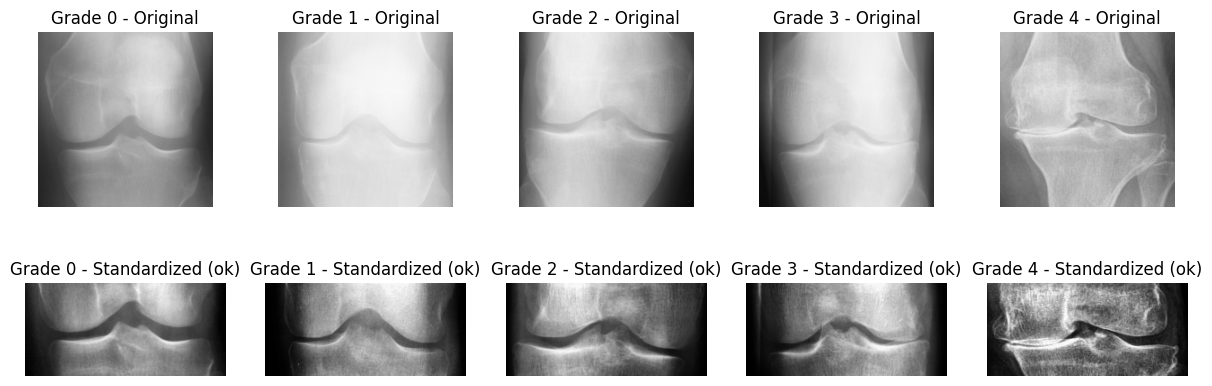

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for k in range(5):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L").resize((224, 224))
    standardized, status = standardize_std(Image.open(path_k))
    axes[0][k].imshow(original, cmap="gray", vmin=0, vmax=255); axes[0][k].set_title(f"Grade {k} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(standardized, cmap="gray", vmin=0, vmax=255); axes[1][k].set_title(f"Grade {k} - Standardized ({status})"); axes[1][k].axis("off")
plt.show()


In [13]:
from tqdm.auto import tqdm


def _keep(batch):
    return batch

class _Standardized(torch.utils.data.Dataset):
    def __init__(self, samples):
        self.samples = samples
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        img = Image.open(self.samples[i][0]).convert("RGB")      # the same way ImageFolder opens an image
        return np.array(standardize_std(img)[0])

def standardize_all(folder_dataset, name):
    loader = DataLoader(_Standardized(folder_dataset.samples), batch_size=64, num_workers=2, collate_fn=_keep)
    arrays = []
    for batch in tqdm(loader, desc=f"standardizing {name}"):
        arrays.extend(batch)
    return [Image.fromarray(a) for a in arrays]


tf_fast = transforms.Compose([
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_tf_fast = transforms.Compose([
    transforms.Grayscale(3),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class CachedFolder(torch.utils.data.Dataset):
    """Same images and labels as the ImageFolder, with the standardization already done."""
    def __init__(self, folder, images, transform):
        self.classes, self.class_to_idx = folder.classes, folder.class_to_idx
        self.samples, self.targets = folder.samples, folder.targets
        self.images, self.transform = images, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.transform(self.images[i]), self.targets[i]

# ---- 3) build the cached datasets and loaders (same names as before) ----
train_plain, val_plain, test_plain = train, val, test          # keep the originals for the check below

train = CachedFolder(train_plain, standardize_all(train_plain, "train"), train_tf_fast)
val   = CachedFolder(val_plain,   standardize_all(val_plain,   "val"),   tf_fast)
test  = CachedFolder(test_plain,  standardize_all(test_plain,  "test"),  tf_fast)

train_loader = DataLoader(train, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=2)

# ---- 4) check: a cached validation image must be identical to the one of the normal pipeline ----
x_cached, _ = val[0]
x_normal, _ = val_plain[0]
print("cached image identical to the normal pipeline:", torch.allclose(x_cached, x_normal, atol=1e-6))
images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))

standardizing train:   0%|          | 0/91 [00:00<?, ?it/s]

standardizing val:   0%|          | 0/13 [00:00<?, ?it/s]

standardizing test:   0%|          | 0/26 [00:00<?, ?it/s]

cached image identical to the normal pipeline: True
batch shape: torch.Size([32, 3, 104, 224])
train: 5778 | val: 826 | test: 1656


# Agnostic Code

In [14]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (DenseNet-201)

## Finetuning

In [15]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [16]:
def train_step(model,
               data_loader,
               loss_fn,
               optim,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optim.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optim.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [17]:
def test_step(model,
               data_loader,
               loss_fn,
               acc_fn,
               device = device):

  test_loss, test_acc = 0.0, 0.0

  model.to(device)

  model.eval() # set model to test/ eval mode

  with torch.inference_mode(): # context manager that disable gradient tracking. reduses memory consumption and sped up execution
    for input, label in data_loader:
      input, label = input.to(device), label.to(device)

      # 1. forward
      output = model(input)

      # 2. calculate the loss
      loss = loss_fn(output, label)
      test_loss += loss
      test_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f'Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}')
    return test_acc

In [18]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc


In [19]:
import json, random, time, copy
import numpy as np
from torchvision import models
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, balanced_accuracy_score

SEEDS = [42, 7, 123]
EPOCHS = 20

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def make_model():
    m = models.densenet201(weights=models.DenseNet201_Weights.DEFAULT)   # finetuning
    m.classifier = nn.Linear(m.classifier.in_features, 5)
    return m.to(device)

@torch.no_grad()
def predict_test(m):
    m.eval()
    preds, labels = [], []
    for x, y in test_loader:
        preds.extend(m(x.to(device)).argmax(dim=1).cpu().numpy())
        labels.extend(y.numpy())
    return np.array(labels), np.array(preds)

def run_one_seed(seed):
    set_seed(seed)
    m = make_model()
    seed_loss_fn = nn.CrossEntropyLoss()
    seed_optim = torch.optim.Adam(m.parameters(), lr=0.001)

    best_acc, best_state = 0.0, copy.deepcopy(m.state_dict())
    for epoch in range(EPOCHS):
        print(f"[seed {seed}] epoch {epoch + 1} / {EPOCHS}")
        train_step(model=m, data_loader=train_loader, loss_fn=seed_loss_fn, optim=seed_optim, acc_fn=accuracy_fn)
        val_acc = test_step(model=m, data_loader=val_loader, loss_fn=seed_loss_fn, acc_fn=accuracy_fn)
        if val_acc > best_acc:                                   # the best epoch is chosen by validation accuracy
            best_acc, best_state = val_acc, copy.deepcopy(m.state_dict())

    m.load_state_dict(best_state)
    y, p = predict_test(m)
    torch.save(best_state, f"densenet201_sara_seed{seed}.pt")
    return {
        "val_acc": best_acc,
        "test_acc": accuracy_score(y, p) * 100,
        "macro_f1": f1_score(y, p, average="macro"),
        "f1_per_class": f1_score(y, p, average=None, labels=[0, 1, 2, 3, 4]).tolist(),
        "qwk": cohen_kappa_score(y, p, weights="quadratic"),
        "balanced_acc": balanced_accuracy_score(y, p) * 100,
    }

results = {}
for s in SEEDS:
    t0 = time.time()
    results[s] = run_one_seed(s)
    r = results[s]
    print(f">>> seed {s}: best val acc {r['val_acc']:.2f}% | TEST acc {r['test_acc']:.2f}% | "
          f"macro-F1 {r['macro_f1']:.4f} | QWK {r['qwk']:.4f} | {(time.time() - t0) / 60:.1f} min\n")
    json.dump(results, open("seed_results.json", "w"), indent=2)     # saved after every seed

Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 167MB/s]


[seed 42] epoch 1 / 20
Train loss: 1.1278, Train acc: 52.1773
Test loss: 1.0708, Test acc: 54.4009
[seed 42] epoch 2 / 20
Train loss: 0.9859, Train acc: 59.0796
Test loss: 1.0261, Test acc: 58.2008
[seed 42] epoch 3 / 20
Train loss: 0.9144, Train acc: 62.0741
Test loss: 1.1249, Test acc: 52.8661
[seed 42] epoch 4 / 20
Train loss: 0.8820, Train acc: 63.3479
Test loss: 1.0943, Test acc: 58.3950
[seed 42] epoch 5 / 20
Train loss: 0.8624, Train acc: 63.7393
Test loss: 0.9224, Test acc: 65.5418
[seed 42] epoch 6 / 20
Train loss: 0.8343, Train acc: 65.1761
Test loss: 0.9430, Test acc: 62.4260
[seed 42] epoch 7 / 20
Train loss: 0.8267, Train acc: 65.7554
Test loss: 0.9726, Test acc: 63.3876
[seed 42] epoch 8 / 20
Train loss: 0.8009, Train acc: 65.9588
Test loss: 25.8138, Test acc: 35.8173
[seed 42] epoch 9 / 20
Train loss: 0.7940, Train acc: 66.4710
Test loss: 0.9201, Test acc: 62.0839
[seed 42] epoch 10 / 20
Train loss: 0.7642, Train acc: 67.8445
Test loss: 3.0970, Test acc: 46.0706
[seed 42

In [20]:
print(f"{'seed':>6} | {'val acc':>8} | {'test acc':>8} | {'macro-F1':>8} | {'QWK':>6} | {'bal. acc':>8}")
for s, r in results.items():
    print(f"{s:>6} | {r['val_acc']:>8.2f} | {r['test_acc']:>8.2f} | {r['macro_f1']:>8.4f} | {r['qwk']:>6.4f} | {r['balanced_acc']:>8.2f}")

print()
for key, name in [("test_acc", "test accuracy %"), ("macro_f1", "macro-F1"), ("qwk", "QWK"), ("balanced_acc", "balanced accuracy %")]:
    v = np.array([r[key] for r in results.values()])
    print(f"{name:>20}: mean {v.mean():.4f} | std {v.std(ddof=1) if len(v) > 1 else 0:.4f} | min {v.min():.4f} | max {v.max():.4f}")

f1s = np.array([r["f1_per_class"] for r in results.values()])       # rows = seeds, columns = grades 0 to 4
print("\nF1 of each grade (mean +- std over the seeds):")
for k in range(5):
    print(f"  Grade {k}: {f1s[:, k].mean():.3f} +- {f1s[:, k].std(ddof=1) if len(f1s) > 1 else 0:.3f}")

print("\nA small std (about 1 point for the accuracy) means the result is stable and does not depend on luck.")

  seed |  val acc | test acc | macro-F1 |    QWK | bal. acc
    42 |    65.61 |    65.46 |   0.5908 | 0.7795 |    60.03
     7 |    67.83 |    66.91 |   0.6584 | 0.8133 |    67.81
   123 |    65.50 |    65.40 |   0.5936 | 0.7977 |    65.01

     test accuracy %: mean 65.9219 | std 0.8547 | min 65.3986 | max 66.9082
            macro-F1: mean 0.6143 | std 0.0383 | min 0.5908 | max 0.6584
                 QWK: mean 0.7969 | std 0.0169 | min 0.7795 | max 0.8133
 balanced accuracy %: mean 64.2826 | std 3.9426 | min 60.0280 | max 67.8127

F1 of each grade (mean +- std over the seeds):
  Grade 0: 0.770 +- 0.005
  Grade 1: 0.153 +- 0.095
  Grade 2: 0.655 +- 0.008
  Grade 3: 0.724 +- 0.064
  Grade 4: 0.770 +- 0.055

A small std (about 1 point for the accuracy) means the result is stable and does not depend on luck.


In [21]:
best_seed = max(results, key=lambda s: results[s]["val_acc"])
print("best seed (by validation accuracy):", best_seed)

model_ft = make_model()
model_ft.load_state_dict(torch.load(f"densenet201_sara_seed{best_seed}.pt", map_location=device, weights_only=True))
model_ft.eval()

loss_fn = nn.CrossEntropyLoss()      # used by the final test cell
acc_fn = accuracy_fn

best seed (by validation accuracy): 7


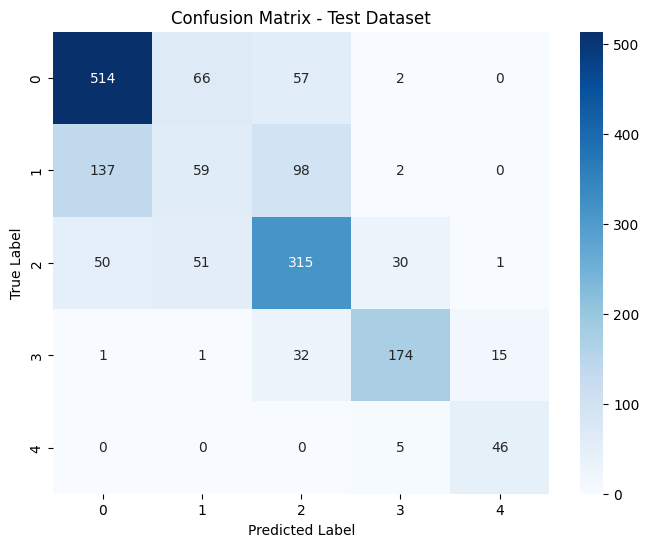

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Put model in evaluation mode
model_ft.eval()
all_preds = []
all_labels = []

# Get predictions on test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model_ft(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)
class_names = train.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [23]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)
import numpy as np

model_ft.eval()
all_preds = []
all_labels = []

with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model_ft(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(train.classes))),
    target_names=train.classes,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(train.classes)))
))

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(all_labels, all_preds) * 100, 2),
    "%"
)

              precision    recall  f1-score   support

           0       0.73      0.80      0.77       639
           1       0.33      0.20      0.25       296
           2       0.63      0.70      0.66       447
           3       0.82      0.78      0.80       223
           4       0.74      0.90      0.81        51

    accuracy                           0.67      1656
   macro avg       0.65      0.68      0.66      1656
weighted avg       0.64      0.67      0.65      1656

Confusion matrix:
[[514  66  57   2   0]
 [137  59  98   2   0]
 [ 50  51 315  30   1]
 [  1   1  32 174  15]
 [  0   0   0   5  46]]
Balanced accuracy: 67.81 %


In [24]:
print("Final test evaluation:")

test_step(
    model=model_ft,
    data_loader=test_loader,
    loss_fn=loss_fn,
    acc_fn=acc_fn
)

Final test evaluation:
Test loss: 0.7859, Test acc: 67.0272


67.02724358974359

In [25]:
y_true, y_pred = predict_test(model_ft)

print(f"accuracy            : {accuracy_score(y_true, y_pred) * 100:.2f} %")
print(f"balanced accuracy   : {balanced_accuracy_score(y_true, y_pred) * 100:.2f} %")
print(f"macro-F1            : {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"weighted-F1         : {f1_score(y_true, y_pred, average='weighted'):.4f}")
print(f"QWK (quadratic kappa): {cohen_kappa_score(y_true, y_pred, weights='quadratic'):.4f}")
print(f"within 1 grade      : {(np.abs(y_true - y_pred) <= 1).mean() * 100:.2f} %   (the prediction is the right grade or next to it)")
print()
for k, f in enumerate(f1_score(y_true, y_pred, average=None, labels=[0, 1, 2, 3, 4])):
    print(f"F1 of Grade {k}: {f:.3f}")

accuracy            : 66.91 %
balanced accuracy   : 67.81 %
macro-F1            : 0.6584
weighted-F1         : 0.6521
QWK (quadratic kappa): 0.8133
within 1 grade      : 93.12 %   (the prediction is the right grade or next to it)

F1 of Grade 0: 0.767
F1 of Grade 1: 0.249
F1 of Grade 2: 0.664
F1 of Grade 3: 0.798
F1 of Grade 4: 0.814


## Heatmap (Grad-CAM)
Shows where the model looked when it decided the grade: the **red areas** influenced the decision the most.
It uses the last dense block of DenseNet201 and the model of the best seed. One test image of each grade is shown, with the real and the predicted grade.

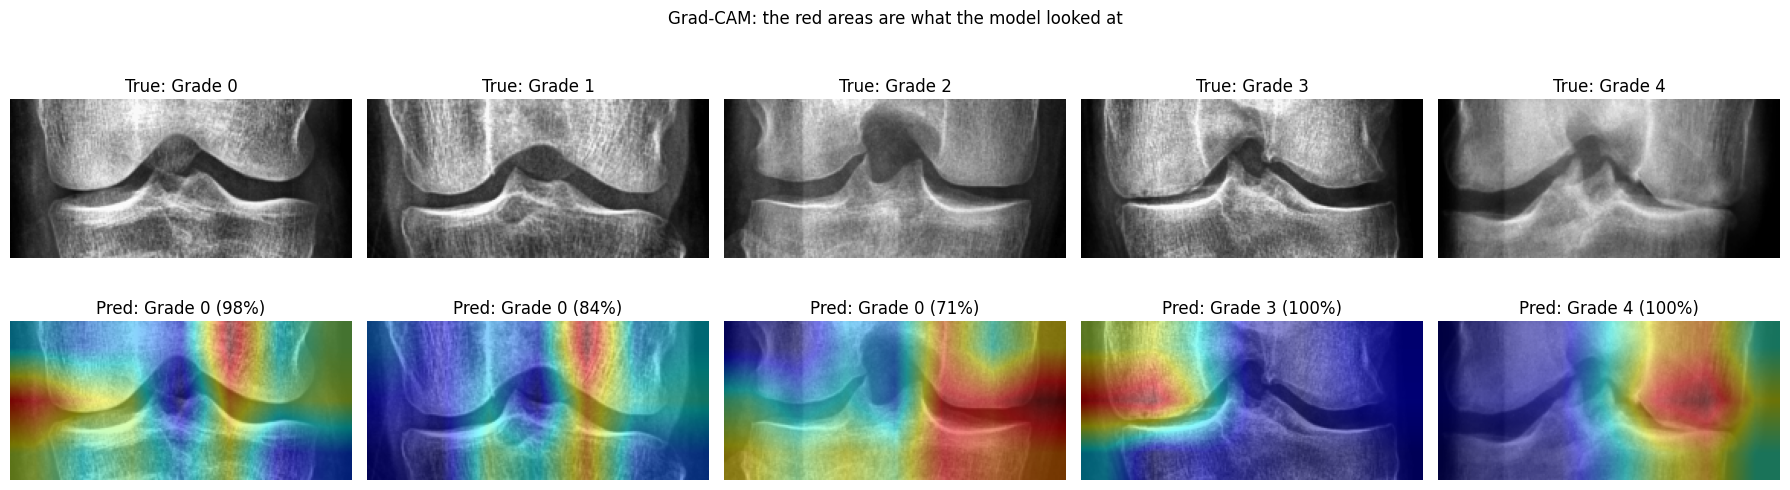

In [26]:
import cv2
import torch.nn.functional as F
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.acts, self.grads = None, None
        self.handle = layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inp, out):
        self.acts = out.detach()
        out.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x, class_idx=None):
        self.model.eval()
        with torch.enable_grad():
            out = self.model(x)
            if class_idx is None:
                class_idx = out.argmax(1).item()
            self.model.zero_grad()
            out[0, class_idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)            # importance of each channel
        cam = F.relu((weights * self.acts).sum(1, keepdim=True))       # weighted sum of the feature maps
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        probs = F.softmax(out, 1)[0].detach().cpu().numpy()
        return cam.cpu().numpy(), class_idx, probs

    def remove(self):
        self.handle.remove()

img_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
img_std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def overlay(x, cam):
    gray = (x.cpu() * img_std + img_mean).clamp(0, 1)[0].numpy()        # back to a normal image
    base = np.uint8(np.stack([gray] * 3, axis=-1) * 255)
    heat = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return base, cv2.addWeighted(base, 0.55, heat, 0.45, 0)

cam_tool = GradCAM(model_ft, model_ft.features.denseblock4)             # last dense block of DenseNet201

fig, axes = plt.subplots(2, 5, figsize=(18, 5.5))
for k in range(5):
    idx = test.targets.index(k)                                          # first test image of grade k
    x, y = test[idx]
    cam, pred, probs = cam_tool(x.unsqueeze(0).to(device))
    base, over = overlay(x, cam)
    axes[0][k].imshow(base); axes[0][k].set_title(f"True: Grade {k}"); axes[0][k].axis("off")
    axes[1][k].imshow(over); axes[1][k].set_title(f"Pred: Grade {pred} ({probs[pred] * 100:.0f}%)"); axes[1][k].axis("off")
plt.suptitle("Grad-CAM: the red areas are what the model looked at")
plt.tight_layout()
plt.savefig("gradcam_densenet201.png", dpi=150)      # a picture for the report
plt.show()

cam_tool.remove()